# A Rashomon set on planted data

`RESPLINTER` finds every tree whose objective is within a factor (1 + θ) of the best one. This notebook fits such a set on a small dataset with a known rule, then looks at the trees, at how much their predictions disagree, at how important each feature is across the set, and at a table of all its trees. The same steps are in `examples/rashomon_demo.py`.

In [1]:
%matplotlib inline
import numpy as np
from sklearn.model_selection import train_test_split

from splinter import RESPLINTER
from splinter.explore import rashomon_table, select
from splinter.rid import compute_rid
from splinter.viz import (multiplicity_summary, plot_multiplicity, plot_rid, plot_rid_cdf,
                          plot_tradeoff, plot_tree)

## 1. Planted toy data

The label is 1 when `dose` lies between 30 and 70 and `age` is below 60, with 5% of labels flipped. `dose_noisy` is a noisy copy of `dose`, and `noise1` and `noise2` are unrelated to the label. The set holds depth-2 trees within 8% of the best objective (`theta=0.08`).

In [2]:
FEATURES = ["dose", "age", "dose_noisy", "noise1", "noise2"]


SETTINGS = dict(max_depth=2, lookahead_depth=1, lgbm_min_samples_leaf=5, beam_width=4,
                reg=0.004, theta=0.08, lgbm_n_estimators=32, cart_closure=False)


def toy_data(n=400, seed=0):
    """Label 1 for a middle dose band (30 to 70) below age 60; 5% of labels flipped."""
    rng = np.random.default_rng(seed)
    dose, age = rng.integers(0, 101, n).astype(float), rng.integers(20, 81, n).astype(float)
    dose_noisy = np.round(dose + rng.normal(0, 8, n))
    X = np.column_stack([dose, age, dose_noisy, rng.uniform(size=n), rng.uniform(size=n)])
    y = ((dose >= 30) & (dose < 70) & (age < 60)).astype(int)
    y ^= rng.random(n) < 0.05
    return X, y

In [3]:
X, y = toy_data()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

## 2. Fit the Rashomon set

In [4]:
rset = RESPLINTER(**SETTINGS).fit(X_train, y_train, feature_names=FEATURES)
print(rset.summary())

RESPLINTER: 316 trees, 19 graph nodes
  Best objective: 0.076000
  Objective bound: 0.082080 (exact inclusion: True)
  Theta bound: 0.082080 (best objective x (1 + theta))
  Best tree certified optimal: no (within the candidate splits)
  Rashomon set: complete for the splits kept by the search
  Fit time: 0.04s


## 3. Two trees from the set

Tree 0 is the best tree; it recovers the planted rule with one three-way split on `dose`. The second tree is drawn at random from the set.

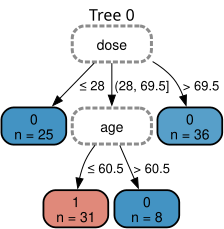

In [5]:
plot_tree(rset.get_tree(0), X_test, y_test, classes=rset.classes_, title="Tree 0")

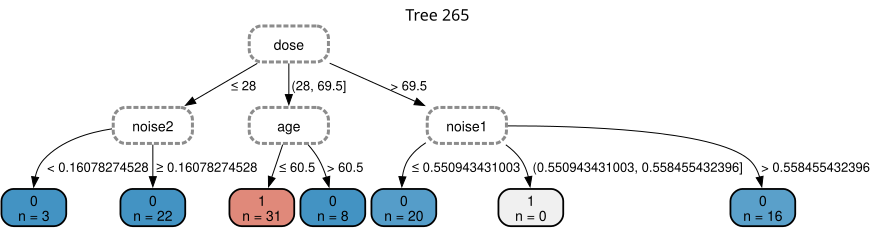

In [6]:
_, (other,) = rset.sample_trees(1, seed=1, at_target=True, return_indices=True)
plot_tree(rset.get_tree(other), X_test, y_test, classes=rset.classes_, title=f"Tree {other}")

## 4. Prediction multiplicity

For each test row, the share of trees in the set that predict 1. Blue bars are rows on which the trees disagree.

316 trees; conflicting predictions on 9.0% of test rows


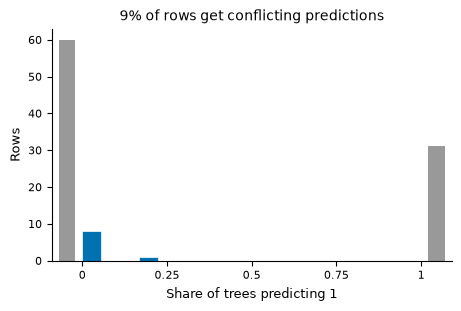

In [7]:
summary = multiplicity_summary(rset, X_test)
print(f"{summary['n_trees']} trees; conflicting predictions on "
      f"{summary['share_conflicting']:.1%} of test rows")
plot_multiplicity(rset, X_test)

## 5. Variable importance across the set

`compute_rid` refits the set on 10 bootstrap samples and records, for every tree, how much the loss grows when a feature's values are scrambled (the Rashomon importance distribution).

RID mean importance: dose 0.263, age 0.161, dose_noisy 0.018, noise1 0.002, noise2 0.002


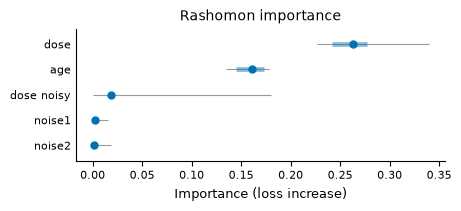

In [8]:
rid = compute_rid(RESPLINTER(**SETTINGS), X_train, y_train, B=10)
ranking = sorted(range(len(FEATURES)), key=lambda j: -rid.mean(j))
print("RID mean importance:", ", ".join(f"{FEATURES[j]} {rid.mean(j):.3f}" for j in ranking))
plot_rid(rid, FEATURES)

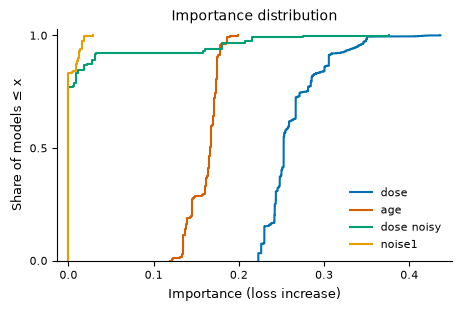

In [9]:
plot_rid_cdf(rid, FEATURES)

## 6. Inspect the set

`rashomon_table` lists every tree with its objective, test accuracy, average explanation size (`aes`: distinct features on a test row's path, averaged over rows), size, widest split (`max_arity`), root feature and features.

In [10]:
table = rashomon_table(rset, X_test, y_test)
print(f"table: {len(table)} rows ({table.attrs['mode']}) of {table.attrs['n_trees']} trees")
table.head()

table: 316 rows (all) of 316 trees


,tree,objective,acc,aes,leaves,min_leaf,depth,max_arity,n_features,root,features
0,0,0.076000,0.94,1.39,4,52,2,3,2,dose,"(age, dose)"
1,1,0.076000,0.94,1.73,4,58,2,3,2,age,"(age, dose)"
2,2,0.076000,0.94,1.73,4,56,2,3,2,age,"(age, dose)"
3,3,0.076667,0.93,1.64,5,1,2,3,3,dose,"(age, dose, dose_noisy)"
4,4,0.077333,0.94,1.75,6,2,2,3,3,dose,"(age, dose, noise1)"


Which features does the set rely on? Every tree uses both `dose` and `age`: filtering either one out leaves no trees.

In [11]:
print(table.features.value_counts().head().to_string())
for name in ("dose", "age"):
    print(f"trees without {name}: {len(select(table, avoids=[name]))}")

features
(age, dose)                        86
(age, dose, noise1)                72
(age, dose, dose_noisy)            62
(age, dose, noise2)                45
(age, dose, dose_noisy, noise1)    28
trees without dose: 0
trees without age: 0


Each marker is one (AES, accuracy) point, sized by its number of trees; the ring marks the best tree.

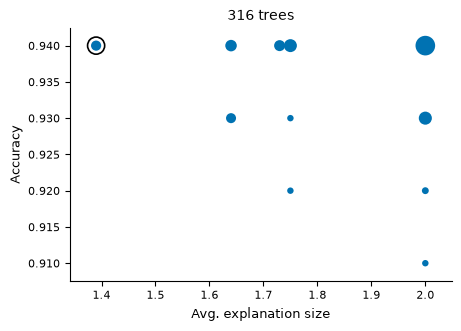

In [12]:
plot_tradeoff(table)

`select` also takes a range `(low, high)` for any numeric column, with `None` for an open end: here accurate trees with short explanations and at least one split with three or more branches.

In [13]:
simple = select(table, acc=(0.93, None), aes=(None, 1.7), max_arity=(3, None))
print(f"accuracy >= 0.93, AES <= 1.7, a split with >= 3 branches: {len(simple)} trees")

accuracy >= 0.93, AES <= 1.7, a split with >= 3 branches: 75 trees


Many near-optimal trees also split on `noise1`, a pure-noise feature (blue). Some of them are as accurate on the test set as the best tree.

114 of 316 trees split on noise1


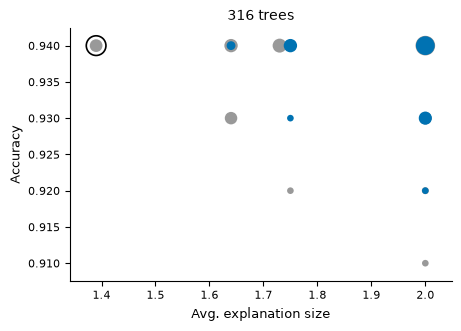

In [14]:
noisy = select(table, uses="noise1")
print(f"{len(noisy)} of {len(table)} trees split on noise1")
plot_tradeoff(table, highlight=noisy)

Any row can be drawn with `plot_tree`; here the best tree that splits on `noise1`.

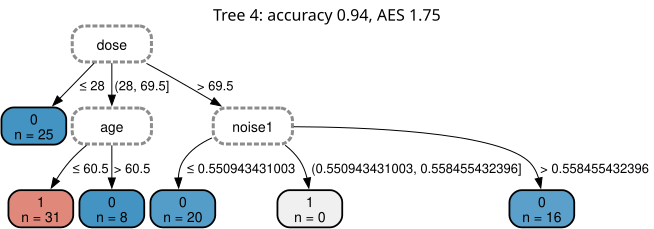

In [15]:
best = noisy.loc[noisy.objective.idxmin()]
plot_tree(rset.get_tree(int(best.tree)), X_test, y_test, classes=rset.classes_,
          title=f"Tree {best.tree}: accuracy {best.acc:.2f}, AES {best.aes:.2f}")

`predicts` keeps the trees that give a row a chosen label. Pick the test row the trees disagree on most evenly; blue trees predict 1 for it.

test row 76: 62 trees predict 1, 254 predict 0 (of 316)


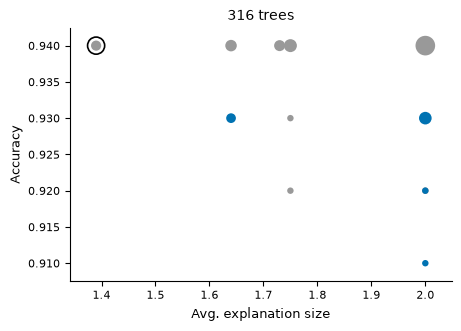

In [16]:
i = int(np.argmin(np.abs(summary["p"] - 0.5)))  # the most evenly split row
yes = select(table, predicts={i: rset.classes_[1]})
no = select(table, predicts={i: rset.classes_[0]})
print(f"test row {i}: {len(yes)} trees predict {rset.classes_[1]}, "
      f"{len(no)} predict {rset.classes_[0]} (of {len(table)})")
plot_tradeoff(table, highlight=yes)

`table` is a pandas DataFrame, so `table.query(...)` works too.